<a href="https://colab.research.google.com/github/HiveCase/DLP-DA5013/blob/main/Week3/DLP_Week3_GA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# !pip install -U "datasets==3.6.0"

In [2]:
from datasets import load_dataset
from pprint import pprint
import matplotlib.pyplot as plt
from scipy.stats import skew

## Question 1: Download the Yelp review dataset `“Yelp/yelp_review_full”`. Split each sample by calling the string method “.split()” and choose the correct statements about the dataset.

 A. The dataset contains close to 99 million words

 B. There are more than 300 samples that contain a single word

 C. There are less than 300 samples that contain only a single word

 D. The average length of a sample is 134.1

 E. The distribution of the length of the samples is right skewed

In [3]:
ds = load_dataset('Yelp/yelp_review_full', split='all')
pprint(ds)

README.md:   0%|          | 0.00/6.72k [00:00<?, ?B/s]

yelp_review_full/train-00000-of-00001.pa(…): reconstructing file:   0%|          |  0.00B /  299MB            

yelp_review_full/train-00000-of-00001.pa(…): downloading bytes:           |  0.00B            

yelp_review_full/test-00000-of-00001.par(…): reconstructing file:   0%|          |  0.00B / 23.5MB            

yelp_review_full/test-00000-of-00001.par(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/650000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Dataset({
    features: ['label', 'text'],
    num_rows: 700000
})


In [4]:
total_words = sum(
    len(example['text'].split())
    for example in ds
)

In [5]:
print(f"The number of words in the given dataset is : {round(total_words/1e6,0)} Million")

The number of words in the given dataset is : 94.0 Million


In [6]:
one_word = sum(
    len(example["text"].split())==1
    for example in ds
)

In [7]:
print(f"Number of samples which contain only one word are: {one_word}")

Number of samples which contain only one word are: 355


In [8]:
avg_len = sum(
    len(example["text"].split())/len(ds)
    for example in ds
)

In [9]:
print(f"Average length of samples is: {round(avg_len,1)}")

Average length of samples is: 134.1


In [10]:
lengths = [len(example["text"].split()) for example in ds]

In [11]:
skewness = skew(lengths)
print(f"Skewness: {skewness}")

Skewness: 2.2343957557732184


In [12]:
if skewness > 0:
    print("The distribution is right-skewed.")
elif skewness < 0:
    print("The distribution is left-skewed.")
else:
    print("The distribution is approximately symmetric.")

The distribution is right-skewed.


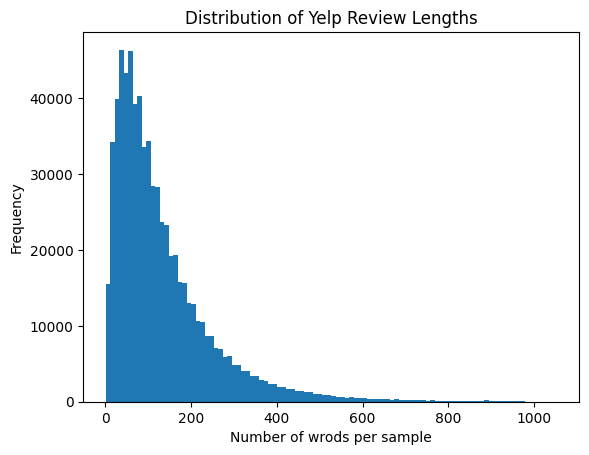

In [13]:
plt.hist(lengths, bins=100)
plt.xlabel("Number of wrods per sample")
plt.ylabel("Frequency")
plt.title("Distribution of Yelp Review Lengths")
plt.show()

## Question 2: Load the “bert-base-uncased” pre-trained tokenizer and choose the correct statements about the tokenizer.

 A. The tokenizer is used for the BERT model with the context length of 512

 B. The tokenizer has 5 special tokens

 C. Tokenizing a sample that contains more than 512 words would result in
 truncation of all tokens beyond the length 512

 D. Tokenizer inserts all the special tokens when it processes a single sample as an input

 E. Tokenizer inserts [CLS] and [SEP] special tokens when it processes a single sample as an input

 F. Tokenizer inserts only [CLS]special token when it processes a single sample as an input

In [14]:
from transformers import AutoTokenizer
tokenizer = AutoTokenizer.from_pretrained('bert-base-uncased')
print(tokenizer)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

BertTokenizer(name_or_path='bert-base-uncased', vocab_size=30522, model_max_length=512, padding_side='right', truncation_side='right', special_tokens={'unk_token': '[UNK]', 'sep_token': '[SEP]', 'pad_token': '[PAD]', 'cls_token': '[CLS]', 'mask_token': '[MASK]'}, added_tokens_decoder={
	0: AddedToken("[PAD]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	100: AddedToken("[UNK]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	101: AddedToken("[CLS]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	102: AddedToken("[SEP]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	103: AddedToken("[MASK]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
})


In [15]:
text = "I love machine learning"
tokens = tokenizer.tokenize(text)
print(tokens)

encoded = tokenizer(text)
print(tokenizer.convert_ids_to_tokens(encoded["input_ids"]))

['i', 'love', 'machine', 'learning']
['[CLS]', 'i', 'love', 'machine', 'learning', '[SEP]']


## Question 3:  Use `“BertConfig”` and `“BertForMaskedLM”` to construct the default (original) BERT model. Choose the correct statements

 A. The model has 12 Bert layers

 B. The model has 6 Bert layers

 C. The model uses absolute position embeddings

 D. The word embedding (token embedding) layer has about 23 million learnable parameters

 E. The total number of parameters in the model is close to 110 million

In [16]:
from transformers import BertConfig, BertForMaskedLM

In [17]:
config = BertConfig()
model = BertForMaskedLM(config)
pprint(model)

BertForMaskedLM(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_a

## Question 4: Double the context length from 512 to 1024 (you can change it in the configuration). Count the number of parameters and enter the change in the number of parameters (in millions) compared to the default configuration.

In [18]:
config_default = BertConfig()
model_default = BertForMaskedLM(config_default)

# Modified model: context length 1024
config_modified = BertConfig(max_position_embeddings=1024)
model_modified = BertForMaskedLM(config_modified)

# Count parameters
default_params = sum(p.numel() for p in model_default.parameters())
modified_params = sum(p.numel() for p in model_modified.parameters())

# Difference in millions
change_millions = (modified_params - default_params) / 1e6

print(f"Default parameters: {default_params / 1e6:.3f} million")
print(f"Modified parameters: {modified_params / 1e6:.3f} million")
print(f"Change: {change_millions:.3f} million")

Default parameters: 109.514 million
Modified parameters: 109.908 million
Change: 0.393 million


## Question 5:  Pack (chunk) the samples such that the length of all the samples in the dataset is 512 (for efficient training). Define a mapping function that implements the following procedure
 1. Take a batch of 1000 samples
 2. Tokenize it to get input IDs and attention mask
 3. Concatenate all the input IDs
 4. Chunk the concatenated IDs into a size of 512
 5. Drop the last chunk if its length is less than 512
 6. Pack all the chunks
 7. Iterate over all the batches in the dataset

## Store the resulting dataset in the variable “ds_chunked”. Enter the total number of samples in the new dataset.
## Note: the batch size should be kept at 1000 while calling "ds.map()" for theanswer to match.

In [19]:
def group_texts(examples):
    # 1–2. Tokenize a batch of samples
    tokenized = tokenizer(
        examples["text"],
        add_special_tokens=True,
        return_attention_mask=True
    )

    # 3. Concatenate input IDs and attention masks
    concatenated = {
        key: sum(tokenized[key], [])
        for key in ["input_ids", "attention_mask"]
    }

    # 4–5. Drop the remainder so the length is divisible by 512
    total_length = (len(concatenated["input_ids"]) // 512) * 512

    # 6. Split into chunks of 512 tokens
    result = {
        key: [
            values[i:i + 512]
            for i in range(0, total_length, 512)
        ]
        for key, values in concatenated.items()
    }

    return result


# 7. Apply the mapping function to batches of 1000 samples
ds_chunked = ds.map(
    group_texts,
    batched=True,
    batch_size=1000,
    remove_columns=ds.column_names
)

print("Total samples in chunked dataset:", len(ds_chunked))

Map:   0%|          | 0/700000 [00:00<?, ? examples/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (1019 > 512). Running this sequence through the model will result in indexing errors


Total samples in chunked dataset: 246695


## Question 6:  Split the new dataset into training and test sets with the test_size=0.05 and seed=42. Use the appropriate data collator function for the MLM objective and set the masking probability to 0.2. Use the data loader from PyTorch to load a batch of samples, and enter the token ID corresponding to the unmasked token

In [20]:
from transformers import DataCollatorForLanguageModeling
from torch.utils.data import DataLoader
import torch

In [21]:
# 1. Split the dataset
split_ds = ds_chunked.train_test_split(
    test_size=0.05,
    seed=42
)
pprint(split_ds)

DatasetDict({
    train: Dataset({
        features: ['input_ids', 'attention_mask'],
        num_rows: 234360
    })
    test: Dataset({
        features: ['input_ids', 'attention_mask'],
        num_rows: 12335
    })
})


In [22]:
train_ds = split_ds["train"]
test_ds = split_ds["test"]

In [23]:

# 2. Data collator for masked language modeling
data_collator = DataCollatorForLanguageModeling(
    tokenizer=tokenizer,
    mlm=True,
    mlm_probability=0.2
)
pprint(data_collator)

DataCollatorForLanguageModeling(tokenizer=BertTokenizer(name_or_path='bert-base-uncased', vocab_size=30522, model_max_length=512, padding_side='right', truncation_side='right', special_tokens={'unk_token': '[UNK]', 'sep_token': '[SEP]', 'pad_token': '[PAD]', 'cls_token': '[CLS]', 'mask_token': '[MASK]'}, added_tokens_decoder={
	0: AddedToken("[PAD]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	100: AddedToken("[UNK]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	101: AddedToken("[CLS]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	102: AddedToken("[SEP]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	103: AddedToken("[MASK]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
}),
                                mlm=True,
                                whole_word_mask=False,
                                mlm_proba

In [24]:
#  3. Create a PyTorch DataLoader
train_loader = DataLoader(
    train_ds,
    batch_size=8,
    shuffle=True,
    collate_fn=data_collator
)

In [25]:
# 4. Load one batch
batch = next(iter(train_loader))

# 5. Find an unmasked token
input_ids = batch["input_ids"]
labels = batch["labels"]

# Labels are -100 at positions not selected for MLM prediction
unmasked_positions = labels == -100

unmasked_token_ids = input_ids[unmasked_positions]

print("Batch input IDs shape:", input_ids.shape)
print("Some unmasked token IDs:", unmasked_token_ids[:20].tolist())
print("First unmasked token ID:", unmasked_token_ids[0].item())

Batch input IDs shape: torch.Size([8, 512])
Some unmasked token IDs: [2053, 10747, 2077, 2035, 4243, 7180, 1012, 1012, 2060, 2616, 1000, 2057, 1005, 2128, 2205, 2000, 2835, 2017, 2065, 2025]
First unmasked token ID: 2053


## Question 7: Create a small BERT model by changing the following hyper-parameters and keeping the other hyper-parameters as is
 • num_hidden_layers = 6

 • hidden size: 384

 • intermediate_size: 1536

 and start training the model with a batch of size 8 for an epoch. What is the loss value at the end of the training?

Note: You may optionally save the checkpoints for every N-th step.

In [26]:
from transformers import BertForMaskedLM
from torch.optim import AdamW
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

In [27]:
config = BertConfig(
    num_hidden_layers=6,
    hidden_size=384,
    intermediate_size=1536
)

In [28]:
model = BertForMaskedLM(config)

In [29]:
print(f"Model parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.2f} million")

Model parameters: 22.74 million


In [30]:
train_loader = DataLoader(
    train_ds,
    batch_size=8,
    shuffle=True,
    collate_fn=data_collator
)

In [31]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

optimizer = AdamW(model.parameters(), lr=5e-5)
model.train()

total_loss = 0.0
num_steps = 0
last_loss = None

In [ ]:
for batch in tqdm(train_loader, desc="Training epoch 1"):
    batch = {k: v.to(device) for k, v in batch.items()}

    optimizer.zero_grad()

    outputs = model(**batch)
    loss = outputs.loss

    loss.backward()
    optimizer.step()

    last_loss = loss.item()
    total_loss += last_loss
    num_steps += 1

Training epoch 1:   0%|          | 0/29295 [00:00<?, ?it/s]

In [ ]:
average_loss = total_loss / num_steps

print(f"Final batch loss: {last_loss:.4f}")
print(f"Average training loss for epoch: {average_loss:.4f}")